# 04 — Isolation Forest Baseline

Results of `python -m flightops.models.train_baseline` (config: `configs/model.yaml`).

- **Training data:** nominal windows in the training split only, excluding duplicate and
  `pressure_invalid` windows. Labels are used only to choose these training windows and for evaluation.
- **Features:** v1 window features (230 = 23 channels × 10 statistics), standardised on the training data.
- **Threshold:** alert on the top 5% of *nominal* validation scores (an alert budget). This needs no
  anomaly labels. A best-F1 threshold chosen on validation is reported for reference only.
- **Evaluation:** stratified test split, plus 5-fold cross-validation that holds out whole aircraft.

In [1]:
%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flightops.config import load_data_config, project_root
from flightops.data.processed import load_processed
from flightops.data.quality import duplicate_mask, parse_flight_record
from flightops.data.schema import FEATURE_NAMES, IDX, LABELS
from flightops.features.build_features import channel_names, load_or_build_features

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
ROOT = project_root()
FIG_DIR = ROOT / "artifacts" / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASS_COLORS = {0: "#4c72b0", 1: "#dd8452", 2: "#55a868", 3: "#c44e52"}

cfg = load_data_config()
X, y = load_processed()
meta = pd.read_csv(cfg.metadata_path, dtype={"flight_record": str})
meta = meta.join(parse_flight_record(meta["flight_record"]))

from sklearn.metrics import precision_recall_curve
report = json.loads((ROOT / "artifacts/reports/baseline_isolation_forest.json").read_text(encoding="utf-8"))
arr = np.load(ROOT / "artifacts/reports/baseline_isolation_forest_scores.npz", allow_pickle=False)
scores, split, labels = arr["scores"], arr["split"], arr["labels"]
P = report["primary_stratified"]
thr = P["test_at_budget"]["binary"]["threshold"]
print("created:", report["created_at"], "| model:", report["model"]["name"], report["model"]["version"])
print("fit windows:", P["n_fit_windows"], "| fit time:", P["fit_seconds"], "s")
display(pd.DataFrame(P["split_counts"]).T)

created: 2026-11-10T09:55:30+00:00 | model: isolation_forest 0.1.0
fit windows: 62678 | fit time: 0.85 s


,Flaps Late Setting,Nominal,Path High,Speed High
train,667,62699,1545,4906
val,143,13437,331,1051
test,143,13436,331,1051
excluded,1,91,0,5


## 1. Test results (stratified split)

In [2]:
rows = {"test @ 5% nominal budget": P["test_at_budget"], "test @ val best-F1 threshold": P["test_at_val_best_f1_threshold"],
        "validation @ 5% budget": P["validation_at_budget"]}
keys = ["precision", "recall", "f1", "fpr", "fnr", "pr_auc", "roc_auc", "anomaly_prevalence"]
display(pd.DataFrame({k: {m: v["binary"][m] for m in keys} for k, v in rows.items()}).T.round(3))
display(pd.DataFrame({k: v["alert_rate_by_class"] for k, v in rows.items()}).T.round(3)
        .rename(columns={"Nominal": "Nominal (false alarm rate)"}))

,precision,recall,f1,fpr,fnr,pr_auc,roc_auc,anomaly_prevalence
test @ 5% nominal budget,0.394,0.294,0.337,0.051,0.706,0.324,0.758,0.102
test @ val best-F1 threshold,0.356,0.350,0.353,0.072,0.650,0.324,0.758,0.102
validation @ 5% budget,0.397,0.290,0.335,0.050,0.710,0.330,0.757,0.102


,Nominal (false alarm rate),Speed High,Path High,Flaps Late Setting
test @ 5% nominal budget,0.051,0.142,0.755,0.343
test @ val best-F1 threshold,0.072,0.189,0.828,0.420
validation @ 5% budget,0.050,0.141,0.740,0.343


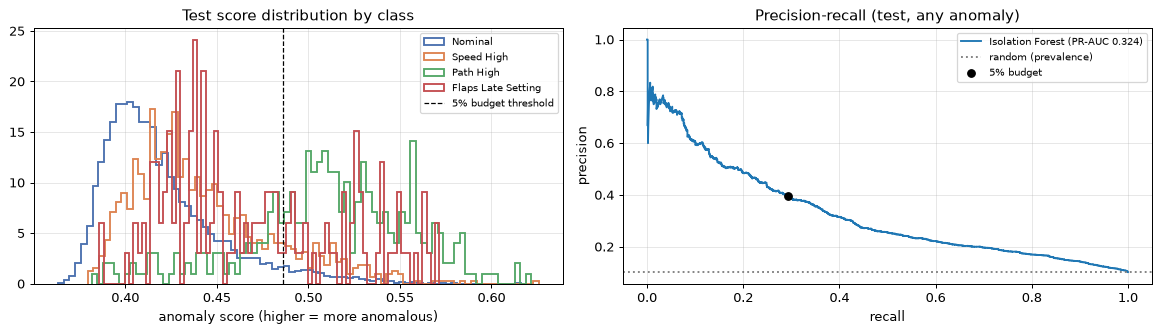

In [3]:
test = split == "test"
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for k, name in LABELS.items():
    axes[0].hist(scores[test & (labels == k)], bins=80, density=True, histtype="step", lw=1.5,
                 color=CLASS_COLORS[k], label=name)
axes[0].axvline(thr, color="k", ls="--", lw=1, label="5% budget threshold")
axes[0].set_xlabel("anomaly score (higher = more anomalous)"); axes[0].set_title("Test score distribution by class")
axes[0].legend(fontsize=8)

prec, rec, _ = precision_recall_curve(labels[test] > 0, scores[test])
axes[1].plot(rec, prec, label=f"Isolation Forest (PR-AUC {P['test_at_budget']['binary']['pr_auc']:.3f})")
axes[1].axhline((labels[test] > 0).mean(), color="gray", ls=":", label="random (prevalence)")
b = P["test_at_budget"]["binary"]; axes[1].scatter([b["recall"]], [b["precision"]], color="k", zorder=3, label="5% budget")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision-recall (test, any anomaly)")
axes[1].legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG_DIR / "04_scores_pr.png")

## 2. Aircraft held out (5-fold)

In [4]:
folds = pd.DataFrame([{"fold": f["fold"], "holds out 657": "657" in f["test_aircraft"], "n_test": f["n_test"],
                       **{m: f["binary"][m] for m in ("anomaly_prevalence", "precision", "recall", "fpr", "pr_auc", "roc_auc")},
                       **{f"detect {k}": v for k, v in f["alert_rate_by_class"].items() if k != "Nominal"}}
                      for f in report["aircraft_held_out"]["folds"]]).set_index("fold")
display(folds.round(3))
display(pd.DataFrame(report["aircraft_held_out"]["summary"]).T.round(3))

,holds out 657,n_test,anomaly_prevalence,precision,recall,fpr,pr_auc,roc_auc,detect Speed High,detect Path High,detect Flaps Late Setting
fold,,,,,,,,,,,
0,False,19742,0.084,0.386,0.343,0.050,0.333,0.812,0.173,0.730,0.344
1,False,19923,0.083,0.410,0.347,0.045,0.368,0.818,0.182,0.711,0.324
2,False,20005,0.082,0.360,0.370,0.058,0.331,0.798,0.196,0.733,0.440
3,True,20072,0.181,0.439,0.182,0.051,0.338,0.663,0.083,0.822,0.389
4,False,19998,0.079,0.377,0.316,0.045,0.327,0.794,0.145,0.681,0.328


,mean,std,min,max
precision,0.394,0.028,0.360,0.439
recall,0.311,0.067,0.182,0.370
f1,0.341,0.043,0.257,0.376
fpr,0.050,0.005,0.045,0.058
pr_auc,0.339,0.015,0.327,0.368
roc_auc,0.777,0.058,0.663,0.818


## 3. Most anomalous test windows

The three highest-scoring test windows, plotted against the median nominal trajectory. This is a sanity check only, not an explanation method.

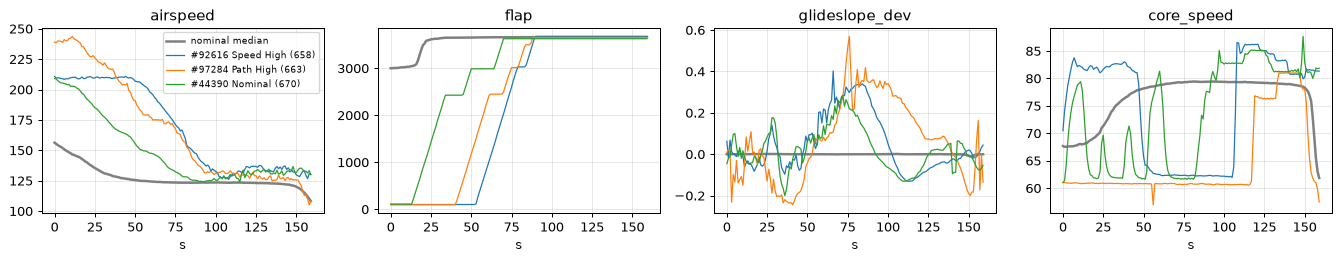

In [5]:
top = np.flatnonzero(test)[np.argsort(-scores[test])[:3]]
nom_idx = np.random.default_rng(0).choice(np.flatnonzero(test & (labels == 0)), 2000, replace=False)
nom_med = np.median(X[np.sort(nom_idx)], axis=0)
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, name in zip(axes, ["airspeed", "flap", "glideslope_dev", "core_speed"]):
    ax.plot(nom_med[:, IDX[name]], color="gray", lw=2, label="nominal median")
    for i in top:
        ax.plot(X[i, :, IDX[name]], lw=1, label=f"#{i} {LABELS[int(labels[i])]} ({meta.aircraft_id[i]})")
    ax.set_title(name); ax.set_xlabel("s")
axes[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(FIG_DIR / "04_top_windows.png")

## 4. Effect of aircraft 657 (label concern from notebook 03)

In [6]:
from flightops.evaluation.metrics import binary_metrics
ac = arr["aircraft"]
rows = {}
for name, m in {"all test windows": test, "test without aircraft 657": test & (ac != "657")}.items():
    b = binary_metrics(labels[m], scores[m], thr)
    rows[name] = {"precision": b["precision"], "recall": b["recall"], "pr_auc": b["pr_auc"],
                  "Speed High detection": float((scores[m & (labels == 1)] >= thr).mean())}
rows["aircraft 657 Speed High only"] = {"Speed High detection": float((scores[test & (labels == 1) & (ac == "657")] >= thr).mean())}
display(pd.DataFrame(rows).T.round(3))

,precision,recall,pr_auc,Speed High detection
all test windows,0.394,0.294,0.324,0.142
test without aircraft 657,0.386,0.365,0.349,0.186
aircraft 657 Speed High only,NaN,NaN,NaN,0.050


## Findings

- **Overall:** at a 5% nominal alert budget, the baseline catches about 29% of anomalous test windows,
  with about 39% precision and PR-AUC ≈ 0.32. Random guessing scores about 0.10 at this prevalence.
  Results on held-out aircraft are similar (PR-AUC 0.34 ± 0.015), so the model is not memorising aircraft.
- **By class:** it detects Path High (~75%) well, Flaps Late (~34%) moderately and Speed High (~14%)
  poorly.
- **Aircraft 657:** its Speed High windows are flagged at the nominal false-alarm rate (~5%), the same
  as nominal flights. This matches the label concern in notebook 03. Excluding 657 raises Speed High
  detection and overall PR-AUC.
- **Room to improve:** notebook 03 found single features that separate each class almost perfectly, but
  the forest spreads its attention over 230 redundant features. Next steps (Phase 3):
  - a reconstruction-based autoencoder;
  - a reduced or decorrelated feature set;
  - a supervised classifier as an upper-bound reference.

These are experimental statistical results on snapshot labels. They are not validated detection
performance for operational use.